## 1. Find Gradient-Informed Threshold

In this section, we use the H2 gradient results to identify a gradient-informed heuristic threshold for the retrieval decision score \(d\).

First, we load the aggregated gradient results and consider only the **Total** data, which combines samples across different hop counts.

For each retrieval ratio, we identify a characteristic decision score based on the gradient curve:

- **`0:3`**: all retrieved documents are non-supporting. We take the \(d\) corresponding to the **maximum positive gradient**.
- **`1:2`**, **`2:1`**, and **`3:0`**: these conditions contain supporting documents. We take the \(d\) corresponding to the **minimum gradient** (the valley) for each condition.

This gives four characteristic decision scores:

\[
d_{0:3}^{\mathrm{peak}},
\quad
d_{1:2}^{\mathrm{valley}},
\quad
d_{2:1}^{\mathrm{valley}},
\quad
d_{3:0}^{\mathrm{valley}}.
\]

We then compute their mean and use it as the gradient-informed heuristic threshold:

\[
\tau_{\mathrm{grad}}
=
\frac{
d_{0:3}^{\mathrm{peak}}
+
d_{1:2}^{\mathrm{valley}}
+
d_{2:1}^{\mathrm{valley}}
+
d_{3:0}^{\mathrm{valley}}
}{4}.
\]

The resulting threshold is used to focus the visualization on the region

\[
d \geq \tau_{\mathrm{grad}},
\]

by removing points with decision scores below the threshold from the plotted gradient curves.

> **Note:** This threshold is a gradient-informed heuristic operating point derived from the observed H2 gradient curves. It is not a directly supervised or mathematically optimal retrieval threshold.

### 1.1 Load H2 Gradient Results

Load the aggregated H2 gradient results from `gradient_summary.csv`.

The file contains the mean gradient of the LM loss with respect to the retrieval decision score \(d\), grouped by hop count, retrieval ratio, and decision score.

In [3]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("gradient_results/plots/gradient_summary.csv")

df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

df.head()

Shape: (528, 5)
Columns: ['hop', 'retrieval_ratio', 'decision_score', 'mean_gradient', 'n_samples']


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
0,2-hop,3:0,0.0000,NaN,0
1,2-hop,3:0,0.0312,NaN,0
2,2-hop,3:0,0.0625,NaN,0
3,2-hop,3:0,0.0938,NaN,0
4,2-hop,3:0,0.1250,NaN,0


### 1.2 Extract Total Data

Select only the `Total` rows from the H2 gradient results.

The `Total` data aggregates the gradient results across all hop counts and is used for determining the gradient-informed threshold.

In [4]:
total_df = df[df["hop"] == "Total"].copy()

print(f"Shape: {total_df.shape}")

total_df.head()

Shape: (132, 5)


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
396,Total,3:0,0.0000,-0.389219,494
397,Total,3:0,0.0312,-0.393704,494
398,Total,3:0,0.0625,-0.169184,494
399,Total,3:0,0.0938,-0.169219,494
400,Total,3:0,0.1250,-0.145530,494


### 1.3 Extract Characteristic Decision Scores

For each retrieval ratio, identify a characteristic decision score from the gradient curve:

- `0:3`: select the decision score with the **maximum positive gradient**.
- `1:2`, `2:1`, `3:0`: select the decision score with the **minimum gradient**.

These points represent the peak or valley of the corresponding gradient curves and will be used to estimate the threshold.

In [5]:
ratios = ["0:3", "1:2", "2:1", "3:0"]

characteristic_rows = {}

for ratio in ratios:
    ratio_df = total_df[
        (total_df["retrieval_ratio"] == ratio) &
        (total_df["n_samples"] > 0)
    ].dropna(subset=["mean_gradient"])

    if ratio == "0:3":
        row = ratio_df.loc[ratio_df["mean_gradient"].idxmax()]
    else:
        row = ratio_df.loc[ratio_df["mean_gradient"].idxmin()]

    characteristic_rows[ratio] = row

characteristic_df = pd.DataFrame(characteristic_rows).T

characteristic_df[
    ["decision_score", "mean_gradient", "n_samples"]
]

,decision_score,mean_gradient,n_samples
0:3,0.4062,0.208989,1024
1:2,0.4375,-0.946976,1024
2:1,0.4375,-1.80872,1024
3:0,0.4375,-2.215442,494


### 1.4 Compute Mean Decision Score

Compute the mean of the characteristic decision scores obtained from the four retrieval ratios.

The resulting mean is used as the gradient-informed heuristic threshold:

\[
\tau_{\mathrm{grad}}
=
\mathrm{mean}
\left(
d_{0:3}^{\mathrm{peak}},
d_{1:2}^{\mathrm{valley}},
d_{2:1}^{\mathrm{valley}},
d_{3:0}^{\mathrm{valley}}
\right).
\]

In [6]:
threshold = characteristic_df["decision_score"].mean()

print(f"Mean decision score: {threshold:.4f}")

Mean decision score: 0.4297


### 1.5 Filter by Gradient-Informed Threshold

Filter the `Total` gradient results using the gradient-informed threshold obtained above.

Only data points with decision scores satisfying

\[
d \geq \tau_{\mathrm{grad}}
\]

are retained for further analysis and visualization.

In [7]:
threshold_df = total_df[
    total_df["decision_score"] >= threshold
].copy()

print(f"Threshold: {threshold:.4f}")
print(f"Shape before filtering: {total_df.shape}")
print(f"Shape after filtering: {threshold_df.shape}")

threshold_df.head()

Threshold: 0.4297
Shape before filtering: (132, 5)
Shape after filtering: (76, 5)


,hop,retrieval_ratio,decision_score,mean_gradient,n_samples
410,Total,3:0,0.4375,-2.215442,494
411,Total,3:0,0.4688,-1.692428,494
412,Total,3:0,0.5000,-1.389683,494
413,Total,3:0,0.5312,-1.038849,494
414,Total,3:0,0.5625,-0.766713,494


Saved: gradient_results\plots\gradient_vs_decision_score_total_with_threshold.png


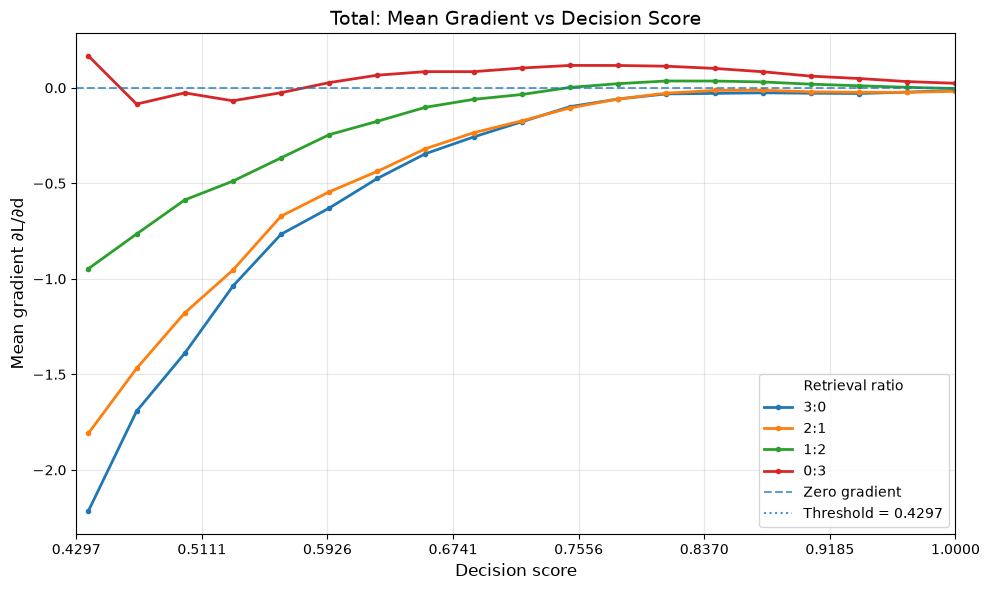

In [8]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


OUTPUT_PATH = Path(
    "gradient_results/plots/gradient_vs_decision_score_total_with_threshold.png"
)

plt.figure(figsize=(10, 6))

for ratio in ["3:0", "2:1", "1:2", "0:3"]:
    ratio_df = threshold_df[
        threshold_df["retrieval_ratio"] == ratio
    ].sort_values("decision_score")

    if ratio_df.empty:
        continue

    plt.plot(
        ratio_df["decision_score"],
        ratio_df["mean_gradient"],
        marker="o",
        markersize=3,
        linewidth=2,
        label=ratio,
    )

# Zero-gradient reference
plt.axhline(
    y=0.0,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label="Zero gradient",
)

# Threshold reference
plt.axvline(
    x=threshold,
    linestyle=":",
    linewidth=1.5,
    alpha=0.8,
    label=f"Threshold = {threshold:.4f}",
)

plt.xlabel(
    "Decision score",
    fontsize=12,
)

plt.ylabel(
    "Mean gradient ∂L/∂d",
    fontsize=12,
)

plt.title(
    "Total: Mean Gradient vs Decision Score",
    fontsize=14,
)

plt.xlim(threshold, 1)

plt.xticks(
    np.linspace(
        threshold,
        1,
        8,
    )
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    title="Retrieval ratio"
)

plt.tight_layout()

# Save plot
plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
)

print(f"Saved: {OUTPUT_PATH}")

plt.show()

## 2. Cost Analysis

In this section, we analyze the effect of the retrieval cost term

$$
J(d)=L_{\mathrm{LM}}(d)+\lambda d
$$

on the gradient with respect to the retrieval decision score \(d\).

The resulting gradient is

$$
\frac{\partial J}{\partial d}
=
\frac{\partial L_{\mathrm{LM}}}{\partial d}+\lambda.
$$

Equivalently, we can analyze a horizontal reference level at

$$
-\lambda.
$$

For a given \(\lambda\):

* if \(g_{\mathrm{LM}}(d)>-\lambda\), then \(g_{\mathrm{LM}}(d)+\lambda>0\), meaning that the cost term dominates the LM-loss gradient at that point;
* if \(g_{\mathrm{LM}}(d)<-\lambda\), then \(g_{\mathrm{LM}}(d)+\lambda<0\), meaning that the LM-loss gradient still dominates the retrieval cost.

The analysis is performed on `threshold_df`, i.e. the H2 gradient results restricted to the decision-score region

$$
d\geq\tau_{\mathrm{grad}}.
$$

### Analysis procedure

We proceed in four steps:

1. **Determine the sweep range for \(-\lambda\)**

   * Find the minimum gradient score in the `0:3` condition.
   * Find the minimum gradient score across all retrieval ratios.
   * Use these two values as the boundaries of the \(-\lambda\) sweep range.

2. **Sweep \(-\lambda\)**
   Generate a sequence of \(-\lambda\) values within this range using a small step size.

3. **Measure cost-dominated points**
   For each \(-\lambda\), count the number of points satisfying

   $$
   g_{\mathrm{LM}}(d)>-\lambda
   $$

   for each retrieval ratio.

   These are the points whose total gradient becomes positive after adding the retrieval cost term \(\lambda d\).

   We pay particular attention to the ratios containing supporting documents:

   * `1:2`
   * `2:1`
   * `3:0`

   because these represent cases where retrieval can provide useful evidence.

4. **Visualize and select \(\lambda\)**
   Plot the number or proportion of positive-gradient points as a function of \(\lambda\).
   The resulting curves show how increasing the retrieval cost progressively changes the balance between the LM-loss gradient and the retrieval cost.

The final \(\lambda\) is selected based on this empirical cost-dominance analysis rather than being arbitrarily specified.


### 2.1 Determine the Minimum Cost Coefficient

We determine the minimum retrieval cost coefficient \(\lambda\) using the `0:3` condition, where all retrieved documents are non-supporting.

The most negative LM-loss gradient in this condition represents the strongest gradient incentive toward increasing the retrieval decision score.

Since

\[
\frac{\partial J}{\partial d}
=
\frac{\partial L_{\mathrm{LM}}}{\partial d}+\lambda,
\]

we choose the minimum \(\lambda\) that can neutralize this strongest negative gradient:

\[
\lambda_{\min}
=
-\min_d
\frac{\partial L_{\mathrm{LM}}}{\partial d}.
\]

The resulting value is used as the initial retrieval cost coefficient for the ART training objective.

In [9]:
# 2.1 Determine the Minimum Cost Coefficient

EPSILON = 0.01

# Most negative LM-loss gradient in the 0:3 condition
min_grad_0_3 = threshold_df[
    threshold_df["retrieval_ratio"] == "0:3"
]["mean_gradient"].min()

# Minimum lambda required to neutralize the strongest negative gradient
lambda_min = -min_grad_0_3

# Add a small epsilon so the total gradient remains positive
lambda_selected = lambda_min + EPSILON

print(f"Minimum gradient (0:3): {min_grad_0_3:.6f}")
print(f"Lambda_min: {lambda_min:.6f}")
print(f"Epsilon: {EPSILON:.6f}")
print(f"Selected lambda: {lambda_selected:.6f}")

# Verify the total gradient at the minimum-gradient point
total_gradient_at_min = min_grad_0_3 + lambda_selected

print(f"Total gradient at minimum: {total_gradient_at_min:.6f}")

Minimum gradient (0:3): -0.085349
Lambda_min: 0.085349
Epsilon: 0.010000
Selected lambda: 0.095349
Total gradient at minimum: 0.010000


### 2.2 Count Positive-Gradient Points

We count the number of decision-score points where the LM-loss gradient remains non-negative after applying the selected retrieval cost coefficient.

Since

\[
\frac{\partial J}{\partial d}
=
\frac{\partial L_{\mathrm{LM}}}{\partial d}
+\lambda_{\mathrm{selected}},
\]

the total gradient is non-negative when

\[
\frac{\partial L_{\mathrm{LM}}}{\partial d}
\geq
-\lambda_{\mathrm{selected}}.
\]

For each retrieval ratio, we count the decision-score points satisfying this condition and report both the count and proportion.

In [10]:
target_ratios = ["0:3", "1:2", "2:1", "3:0"]

results = []

for ratio in target_ratios:
    ratio_df = threshold_df[
        threshold_df["retrieval_ratio"] == ratio
    ].dropna(subset=["mean_gradient"])

    # Count points where total gradient >= 0
    positive_count = (
        ratio_df["mean_gradient"] >= -lambda_selected
    ).sum()

    total_count = len(ratio_df)

    results.append({
        "retrieval_ratio": ratio,
        "positive_count": positive_count,
        "total_count": total_count,
        "positive_ratio": positive_count / total_count,
    })

cost_summary_df = pd.DataFrame(results)

print(cost_summary_df)

  retrieval_ratio  positive_count  total_count  positive_ratio
0             0:3              19           19        1.000000
1             1:2              11           19        0.578947
2             2:1               8           19        0.421053
3             3:0               8           19        0.421053


### 2.3 Visualize Cost-Dominated Region

The mean LM-loss gradients are plotted against the decision score for each retrieval ratio.

The cost boundary is defined as

\[
\frac{\partial L_{\mathrm{LM}}}{\partial d}
=
-\lambda_{\mathrm{selected}}.
\]

When

\[
\frac{\partial L_{\mathrm{LM}}}{\partial d}
\geq
-\lambda_{\mathrm{selected}},
\]

the total gradient becomes non-negative:

\[
\frac{\partial J}{\partial d}
=
\frac{\partial L_{\mathrm{LM}}}{\partial d}
+
\lambda_{\mathrm{selected}}
\geq 0.
\]

Therefore, gradient descent has a tendency to decrease the retrieval decision score \(d\).

The region satisfying this condition is highlighted in light red, while the region where the LM-loss gradient dominates the retrieval cost is highlighted in light blue.

Saved: gradient_results\plots\gradient_vs_decision_score_total_with_threshold_and_cost.png


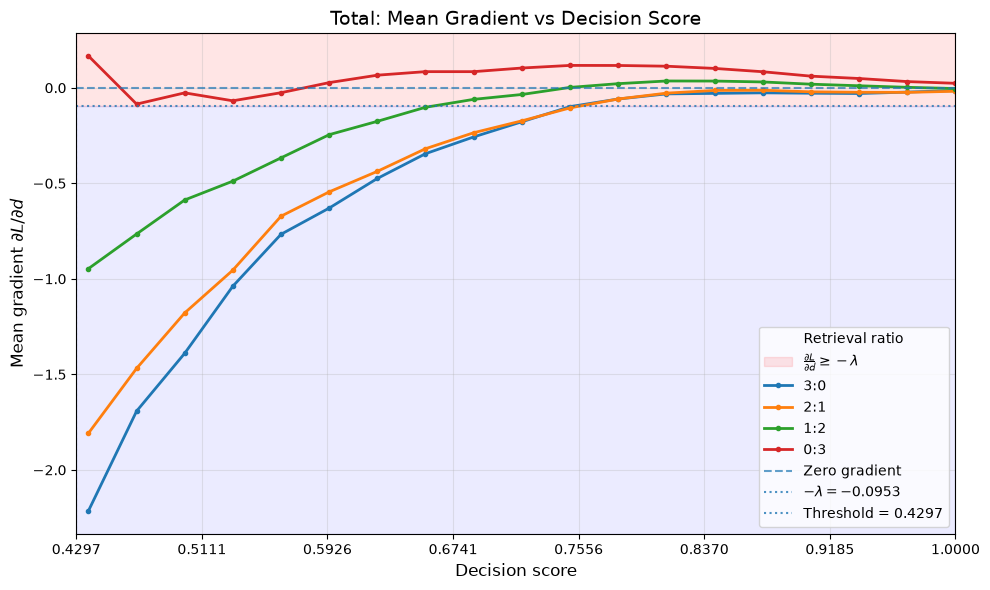

: 

In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


OUTPUT_PATH = Path(
    "gradient_results/plots/"
    "gradient_vs_decision_score_total_with_threshold_and_cost.png"
)

plt.figure(figsize=(10, 6))

# Cost boundary
cost_boundary = -lambda_selected

# Determine y-axis limits from the data
gradient_values = threshold_df["mean_gradient"].dropna()

y_min = gradient_values.min()
y_max = gradient_values.max()

y_margin = 0.05 * (y_max - y_min)

y_min -= y_margin
y_max += y_margin

plt.ylim(y_min, y_max)

# Region where total gradient >= 0
plt.axhspan(
    cost_boundary,
    y_max,
    color="red",
    alpha=0.10,
    label=r"$\frac{\partial L}{\partial d} \geq -\lambda$",
)

# Region where total gradient < 0
plt.axhspan(
    y_min,
    cost_boundary,
    color="blue",
    alpha=0.08,
)

# Plot gradient curves
for ratio in ["3:0", "2:1", "1:2", "0:3"]:
    ratio_df = threshold_df[
        threshold_df["retrieval_ratio"] == ratio
    ].sort_values("decision_score")

    if ratio_df.empty:
        continue

    plt.plot(
        ratio_df["decision_score"],
        ratio_df["mean_gradient"],
        marker="o",
        markersize=3,
        linewidth=2,
        label=ratio,
    )

# Zero-gradient reference
plt.axhline(
    y=0.0,
    linestyle="--",
    linewidth=1.5,
    alpha=0.7,
    label="Zero gradient",
)

# Cost boundary reference
plt.axhline(
    y=cost_boundary,
    linestyle=":",
    linewidth=1.5,
    alpha=0.8,
    label=fr"$-\lambda = {cost_boundary:.4f}$",
)

# Threshold reference
plt.axvline(
    x=threshold,
    linestyle=":",
    linewidth=1.5,
    alpha=0.8,
    label=f"Threshold = {threshold:.4f}",
)

plt.xlabel(
    "Decision score",
    fontsize=12,
)

plt.ylabel(
    r"Mean gradient $\partial L/\partial d$",
    fontsize=12,
)

plt.title(
    "Total: Mean Gradient vs Decision Score",
    fontsize=14,
)

plt.xlim(threshold, 1)

plt.xticks(
    np.linspace(
        threshold,
        1,
        8,
    )
)

plt.grid(
    True,
    alpha=0.3,
)

plt.legend(
    title="Retrieval ratio"
)

plt.tight_layout()

# Save plot
plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight",
)

print(f"Saved: {OUTPUT_PATH}")

plt.show()